# Hotel Booking Cancellation: How Much Do Leakage and Split Choice Inflate Results?

**Dataset:** Hotel Booking Demand (Antonio, Almeida, Nunes, Data in Brief, 2019, doi:10.1016/j.dib.2018.11.126). Kaggle copy: jessemostipak/hotel-booking-demand.

**Target:** `is_canceled` (1 = cancelled). **Type:** binary classification.

**Project questions**
1. Can booking details predict whether a booking will be cancelled?
2. Which model performs best on PR-AUC and recall, not just accuracy?
3. How much do leaky columns and the train/test split method inflate the scores?

Cells marked **WRITE YOURSELF** are for your own interpretation. The course requires your own words there.

## 0. Setup

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import sklearn, xgboost, lightgbm
from sklearn.base import clone
from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
FAST = os.environ.get("FAST") == "1"          # set FAST=1 for a quick dry run
DATA_PATH = os.environ.get("HOTEL_CSV", "data/raw/hotel_bookings.csv")
DROP_DUPLICATES = True

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__)

Python 3.12.10 | pandas 3.0.6 | sklearn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0


## 1. Data loading and understanding
Rubric items: rows and columns, target, features, dtypes, missing values, duplicates, basic statistics.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
print("Target: is_canceled | input features:", df.shape[1] - 1)
display(df.dtypes.to_frame("dtype").T)
print("Missing values:")
print(df.isna().sum()[lambda s: s > 0])
print("Exact duplicate rows:", df.duplicated().sum())
display(df.describe().T)

Rows, columns: (119390, 32)
Target: is_canceled | input features: 31


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
dtype,str,int64,int64,int64,str,int64,int64,int64,int64,int64,...,str,float64,float64,int64,str,float64,int64,int64,str,str


Missing values:
children         4
country        488
agent        16340
company     112593
dtype: int64
Exact duplicate rows: 31994


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


**WRITE YOURSELF:** what is this dataset (two hotels, bookings, period), why does predicting cancellation matter,
and what do the key columns mean (`lead_time`, `deposit_type`, `market_segment`, `adr`, `reservation_status`).

## 2. Exploratory data analysis

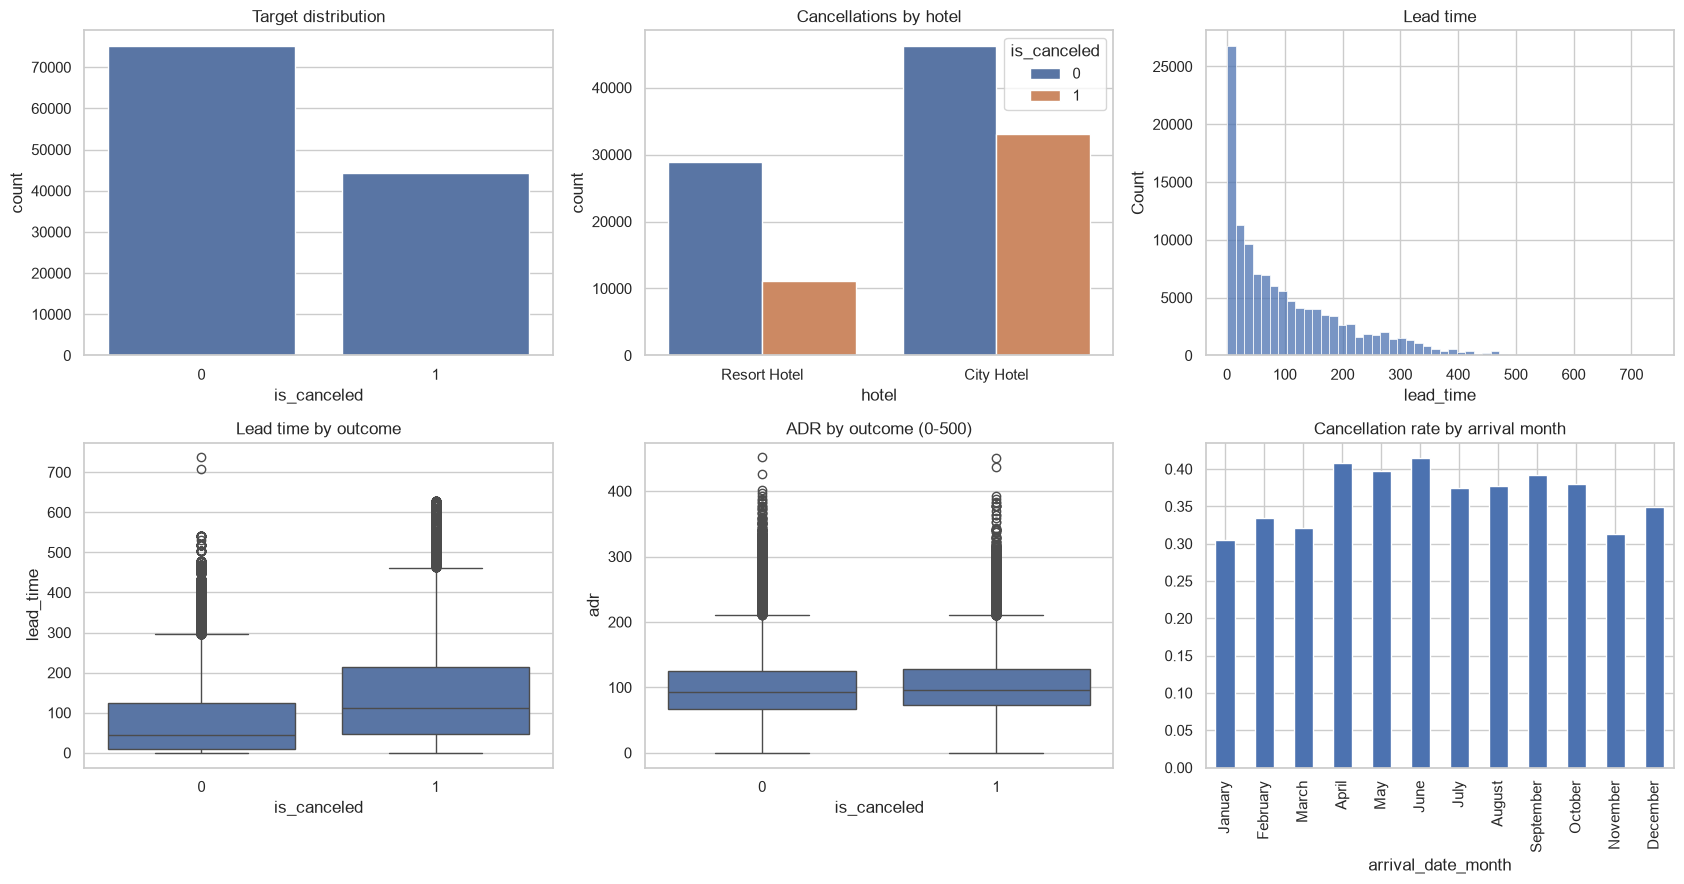

Class balance:
is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64


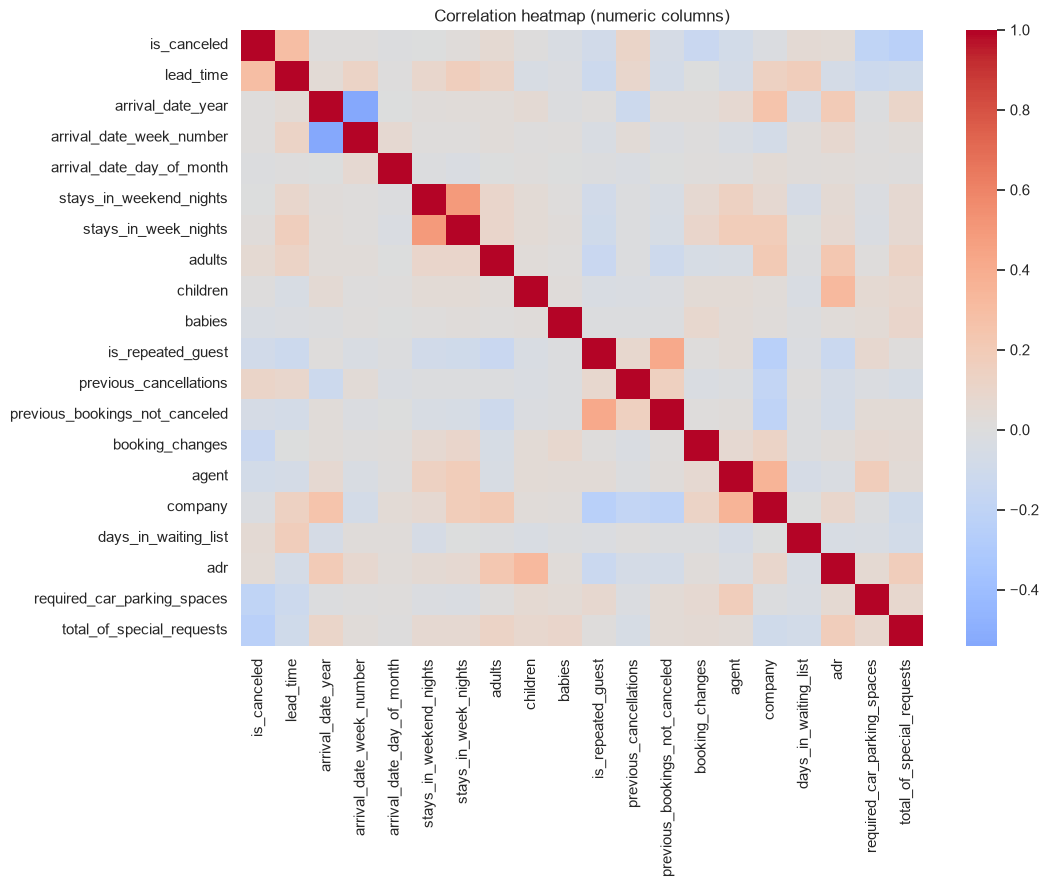

,mean,count
deposit_type,,
No Deposit,0.284,104641
Non Refund,0.994,14587
Refundable,0.222,162


,mean,count
market_segment,,
Online TA,0.367,56477
Offline TA/TO,0.343,24219
Groups,0.611,19811
Direct,0.153,12606
Corporate,0.187,5295
Complementary,0.131,743
Aviation,0.219,237
Undefined,1.000,2


,mean,count
customer_type,,
Transient,0.407,89613
Transient-Party,0.254,25124
Contract,0.310,4076
Group,0.102,577


In [3]:
MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.countplot(x="is_canceled", data=df, ax=ax[0, 0]); ax[0, 0].set_title("Target distribution")
sns.countplot(x="hotel", hue="is_canceled", data=df, ax=ax[0, 1]); ax[0, 1].set_title("Cancellations by hotel")
sns.histplot(df["lead_time"], bins=50, ax=ax[0, 2]); ax[0, 2].set_title("Lead time")
sns.boxplot(x="is_canceled", y="lead_time", data=df, ax=ax[1, 0]); ax[1, 0].set_title("Lead time by outcome")
sns.boxplot(x="is_canceled", y="adr", data=df[df["adr"].between(0, 500)], ax=ax[1, 1]); ax[1, 1].set_title("ADR by outcome (0-500)")
rate = df.groupby("arrival_date_month")["is_canceled"].mean().reindex(MONTHS)
rate.plot(kind="bar", ax=ax[1, 2]); ax[1, 2].set_title("Cancellation rate by arrival month")
plt.tight_layout(); plt.show()

print("Class balance:"); print(df["is_canceled"].value_counts(normalize=True).round(3))

plt.figure(figsize=(11, 8))
sns.heatmap(df.select_dtypes("number").corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap (numeric columns)"); plt.show()

for col in ["deposit_type", "market_segment", "customer_type"]:
    display(df.groupby(col)["is_canceled"].agg(["mean", "count"]).round(3).sort_values("count", ascending=False))

**WRITE YOURSELF:** interpret each graph. What does the class balance mean for metric choice? Why does lead time separate the
classes? Which columns look suspicious (check what `reservation_status` and `deposit_type` do to the target)?

## 3. Preprocessing and splits
Decisions to explain in the report:
- Missing `children` set to 0, missing `agent` set to "0" (no agent), `company` dropped (about 94% missing), missing `country` set to "UNK".
- Rows with zero guests and rows with negative or extreme `adr` removed using fixed business rules (not statistics from the data, to avoid leakage).
- Exact duplicates dropped before splitting, because identical rows in both train and test inflate random-split scores.
- Scaling, imputing and encoding are fit on the training set only, inside a sklearn Pipeline.

In [4]:
d = df.copy()
d["children"] = d["children"].fillna(0)
d["agent"] = d["agent"].fillna(0).astype(int).astype(str)
d["country"] = d["country"].fillna("UNK")
d = d.drop(columns=["company"])
d = d[(d["adults"] + d["children"] + d["babies"]) > 0]
d = d[(d["adr"] >= 0) & (d["adr"] < 1000)]

month_num = {m: i + 1 for i, m in enumerate(MONTHS)}
d["arrival_date"] = pd.to_datetime(dict(year=d["arrival_date_year"],
                                        month=d["arrival_date_month"].map(month_num),
                                        day=d["arrival_date_day_of_month"]))
d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
d["total_guests"] = d["adults"] + d["children"] + d["babies"]
d["reservation_status_date"] = (pd.to_datetime(d["reservation_status_date"]) - pd.Timestamp("2014-01-01")).dt.days

if DROP_DUPLICATES:
    d = d.drop_duplicates()
d = d.sort_values("arrival_date").reset_index(drop=True)
print("Rows after cleaning:", len(d))

Rows after cleaning: 87221


### Feature sets (the audit factor)
- `leaky`: everything, including `reservation_status` and `reservation_status_date`, which are only known after the outcome.
- `no_status`: drops those two columns.
- `clean`: also drops `country`, `deposit_type`, `assigned_room_type`, `booking_changes`.

`country` is flagged in the 2026 Information Technology & Tourism hotel paper because it defaults to Portugal until check-in.
The other three are **my hypotheses, not confirmed facts**. Test them and report what you find. If they turn out harmless, say so.

In [5]:
TARGET = "is_canceled"
DROP_ALWAYS = [TARGET, "arrival_date", "arrival_date_year"]   # year dropped: test period has unseen year values
DEFINITE_LEAK = ["reservation_status", "reservation_status_date"]
RISKY = ["country", "deposit_type", "assigned_room_type", "booking_changes"]

all_cols = [c for c in d.columns if c not in DROP_ALWAYS]
FEATURE_SETS = {
    "leaky": all_cols,
    "no_status": [c for c in all_cols if c not in DEFINITE_LEAK],
    "clean": [c for c in all_cols if c not in DEFINITE_LEAK + RISKY],
}
for k, v in FEATURE_SETS.items():
    print(k, len(v), "features")

idx = d.index.to_numpy()
cut = int(len(idx) * 0.70)
tr_rand, te_rand = train_test_split(idx, test_size=0.30, stratify=d[TARGET], random_state=SEED)
splits = {"chronological": (idx[:cut], idx[cut:]), "random_stratified": (tr_rand, te_rand)}

for name, (a, b) in splits.items():
    print(f"{name}: train {len(a)}, test {len(b)} | cancel rate train {d.loc[a, TARGET].mean():.3f}, test {d.loc[b, TARGET].mean():.3f}")
a, b = splits["chronological"]
print("Chronological train arrivals:", d.loc[a, "arrival_date"].min().date(), "to", d.loc[a, "arrival_date"].max().date())
print("Chronological test arrivals: ", d.loc[b, "arrival_date"].min().date(), "to", d.loc[b, "arrival_date"].max().date())

leaky 31 features
no_status 29 features
clean 25 features
chronological: train 61054, test 26167 | cancel rate train 0.251, test 0.331
random_stratified: train 61054, test 26167 | cancel rate train 0.275, test 0.275
Chronological train arrivals: 2015-07-01 to 2017-02-24
Chronological test arrivals:  2017-02-24 to 2017-08-31


**WRITE YOURSELF:** why 70/30 chronological by arrival date (time-based split, allowed by the brief). Note the limitation:
the data starts in July 2015, so the test period may not cover every month. Check the printed date ranges and say what it means.

## 4. Models, baseline and evaluation helpers

In [6]:
def get_models():
    return {
        "Dummy (prior)": DummyClassifier(strategy="prior"),
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=100 if FAST else 300, min_samples_leaf=5,
                                                n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, subsample=0.8,
                                 colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1, random_state=SEED),
        "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                   n_jobs=-1, random_state=SEED, verbose=-1),
    }


def build_preprocessor(X):
    num = X.select_dtypes("number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=0.005))]), cat),
    ])


def evaluate(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "brier": brier_score_loss(y_true, proba),
    }


def run(split_name, fs_name, models=None):
    tr, te = splits[split_name]
    cols = FEATURE_SETS[fs_name]
    Xtr, Xte = d.loc[tr, cols], d.loc[te, cols]
    ytr, yte = d.loc[tr, TARGET], d.loc[te, TARGET]
    rows, fitted = [], {}
    for name, model in (models or get_models()).items():
        pipe = Pipeline([("prep", build_preprocessor(Xtr)), ("model", model)])
        pipe.fit(Xtr, ytr)
        proba = pipe.predict_proba(Xte)[:, 1]
        rows.append({"split": split_name, "features": fs_name, "model": name, **evaluate(yte, proba)})
        fitted[name] = (pipe, proba)
    return pd.DataFrame(rows), fitted, yte

## 5. Main benchmark (chronological split, clean features)
This is the setting you report as the headline result.

In [7]:
res_main, fitted_main, y_test_main = run("chronological", "clean")
display(res_main.drop(columns=["split", "features"]).round(4))

,model,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,brier
0,Dummy (prior),0.6685,0.0000,0.0000,1.0000,0.0000,0.5000,0.3315,0.2281
1,Logistic Regression,0.7507,0.6707,0.4871,0.8814,0.5643,0.7881,0.6518,0.1706
2,Decision Tree,0.7263,0.6280,0.4274,0.8745,0.5086,0.7648,0.5920,0.1861
3,Random Forest,0.7414,0.6920,0.3960,0.9126,0.5037,0.7916,0.6241,0.1738
4,XGBoost,0.7432,0.6703,0.4433,0.8919,0.5337,0.7932,0.6398,0.1748
5,LightGBM,0.7416,0.6741,0.4267,0.8977,0.5226,0.7927,0.6395,0.1749


**WRITE YOURSELF:** do the models beat the dummy baseline? Compare models on PR-AUC, recall and F1, not accuracy alone.
Why might tree ensembles beat Logistic Regression here?

## 6. Hyperparameter tuning
Randomized search with time-ordered cross-validation inside the training set (no shuffling, so no future leakage).

In [8]:
tr, te = splits["chronological"]
cols = FEATURE_SETS["clean"]
Xtr, ytr, Xte, yte = d.loc[tr, cols], d.loc[tr, TARGET], d.loc[te, cols], d.loc[te, TARGET]

search_space = {
    "XGBoost": (XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=SEED),
                {"model__max_depth": [4, 6, 8], "model__learning_rate": [0.03, 0.05, 0.1],
                 "model__n_estimators": [200, 400], "model__min_child_weight": [1, 5]}),
    "LightGBM": (LGBMClassifier(n_jobs=-1, random_state=SEED, verbose=-1),
                 {"model__num_leaves": [15, 31, 63], "model__learning_rate": [0.03, 0.05, 0.1],
                  "model__n_estimators": [200, 400], "model__min_child_samples": [20, 50]}),
}
tuned_rows, best_params = [], {}
for name, (est, grid) in search_space.items():
    pipe = Pipeline([("prep", build_preprocessor(Xtr)), ("model", est)])
    s = RandomizedSearchCV(pipe, grid, n_iter=2 if FAST else 8, cv=TimeSeriesSplit(n_splits=3),
                           scoring="average_precision", random_state=SEED, n_jobs=1)
    s.fit(Xtr, ytr)
    proba = s.best_estimator_.predict_proba(Xte)[:, 1]
    tuned_rows.append({"model": name + " (tuned)", **evaluate(yte, proba)})
    best_params[name] = s.best_params_

display(pd.DataFrame(tuned_rows).round(4))
print(best_params)

,model,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,brier
0,XGBoost (tuned),0.7355,0.6770,0.3866,0.9085,0.4921,0.7939,0.6468,0.1730
1,LightGBM (tuned),0.7400,0.6803,0.4067,0.9052,0.5091,0.7954,0.6428,0.1737


{'XGBoost': {'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.05}, 'LightGBM': {'model__num_leaves': 15, 'model__n_estimators': 200, 'model__min_child_samples': 20, 'model__learning_rate': 0.05}}


**WRITE YOURSELF:** which parameters you searched, why, and how tuning changed PR-AUC compared with the untuned versions above.

## 7. The audit: split method x feature set
Every model is run in all six settings. The "inflation" column is random-split score minus chronological-split score.

roc_auc


split                          chronological  random_stratified  \
model               features                                      
Decision Tree       clean             0.7648             0.8203   
                    leaky             1.0000             1.0000   
                    no_status         0.8102             0.8787   
LightGBM            clean             0.7927             0.8493   
                    leaky             1.0000             1.0000   
                    no_status         0.8541             0.9127   
Logistic Regression clean             0.7881             0.8075   
                    leaky             1.0000             1.0000   
                    no_status         0.8393             0.8619   
Random Forest       clean             0.7916             0.8512   
                    leaky             1.0000             1.0000   
                    no_status         0.8484             0.9074   
XGBoost             clean             0.7932             0.8530   
                    leaky             1.0000             1.0000   
                    no_status         0.8532             0.9154   

split                          inflation (random - chrono)  
model               features                                
Decision Tree       clean                           0.0555  
                    leaky                           0.0000  
                    no_status                       0.0685  
LightGBM            clean                           0.0566  
                    leaky                           0.0000  
                    no_status                       0.0586  
Logistic Regression clean                           0.0195  
                    leaky                           0.0000  
                    no_status                       0.0226  
Random Forest       clean                           0.0596  
                    leaky                           0.0000  
                    no_status                       0.0589  
XGBoost             clean                           0.0598  
                    leaky                           0.0000  
                    no_status                       0.0622

pr_auc


split                          chronological  random_stratified  \
model               features                                      
Decision Tree       clean             0.5920             0.6551   
                    leaky             1.0000             1.0000   
                    no_status         0.6616             0.7320   
LightGBM            clean             0.6395             0.7097   
                    leaky             1.0000             1.0000   
                    no_status         0.7193             0.8019   
Logistic Regression clean             0.6518             0.6406   
                    leaky             1.0000             1.0000   
                    no_status         0.7002             0.6919   
Random Forest       clean             0.6241             0.7091   
                    leaky             1.0000             1.0000   
                    no_status         0.7008             0.7903   
XGBoost             clean             0.6398             0.7170   
                    leaky             1.0000             1.0000   
                    no_status         0.7173             0.8070   

split                          inflation (random - chrono)  
model               features                                
Decision Tree       clean                           0.0631  
                    leaky                           0.0000  
                    no_status                       0.0704  
LightGBM            clean                           0.0702  
                    leaky                           0.0000  
                    no_status                       0.0826  
Logistic Regression clean                          -0.0112  
                    leaky                           0.0000  
                    no_status                      -0.0084  
Random Forest       clean                           0.0850  
                    leaky                           0.0000  
                    no_status                       0.0895  
XGBoost             clean                           0.0772  
                    leaky                           0.0000  
                    no_status                       0.0897

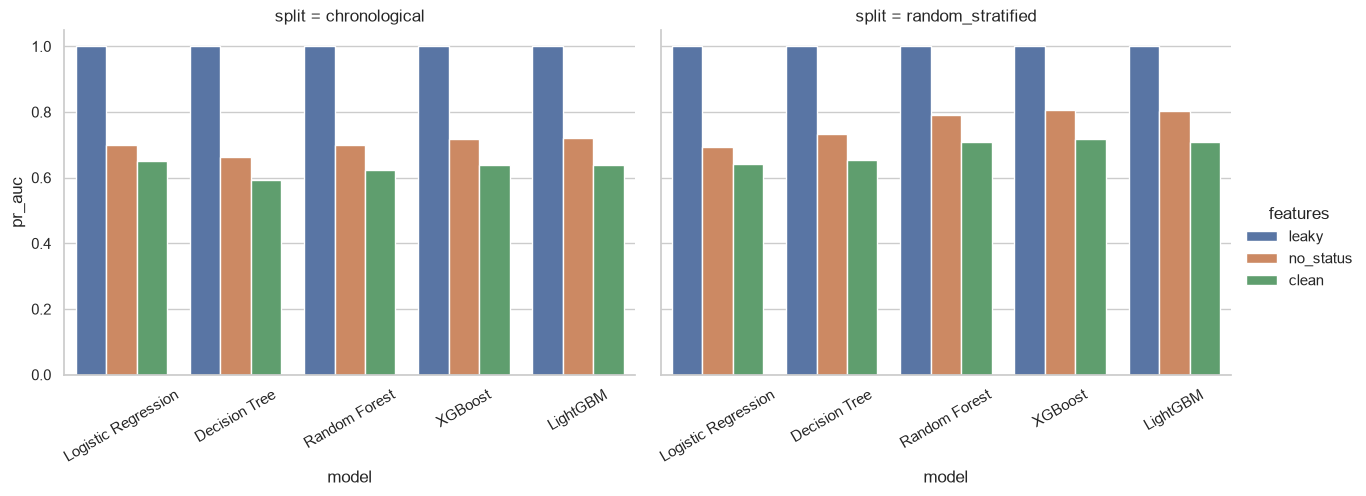

In [9]:
audit = pd.concat([run(sp, fs)[0] for sp in splits for fs in FEATURE_SETS], ignore_index=True)
audit.to_csv("audit_results.csv", index=False)
strong = audit[audit["model"] != "Dummy (prior)"]

for metric in ["roc_auc", "pr_auc"]:
    p = strong.pivot_table(index=["model", "features"], columns="split", values=metric)
    p["inflation (random - chrono)"] = p["random_stratified"] - p["chronological"]
    print(metric)
    display(p.round(4))

g = sns.catplot(data=strong, x="model", y="pr_auc", hue="features", col="split", kind="bar", height=4.5, aspect=1.4)
for a_ in g.axes.flat:
    a_.tick_params(axis="x", rotation=30)
plt.show()

**WRITE YOURSELF:** this is your key result. Which factor inflates scores more, the leaky columns or the random split?
Do `country`, `deposit_type`, `assigned_room_type` and `booking_changes` matter? Report numbers, including cases where the effect is small.

## 8. Result plots for the main setting

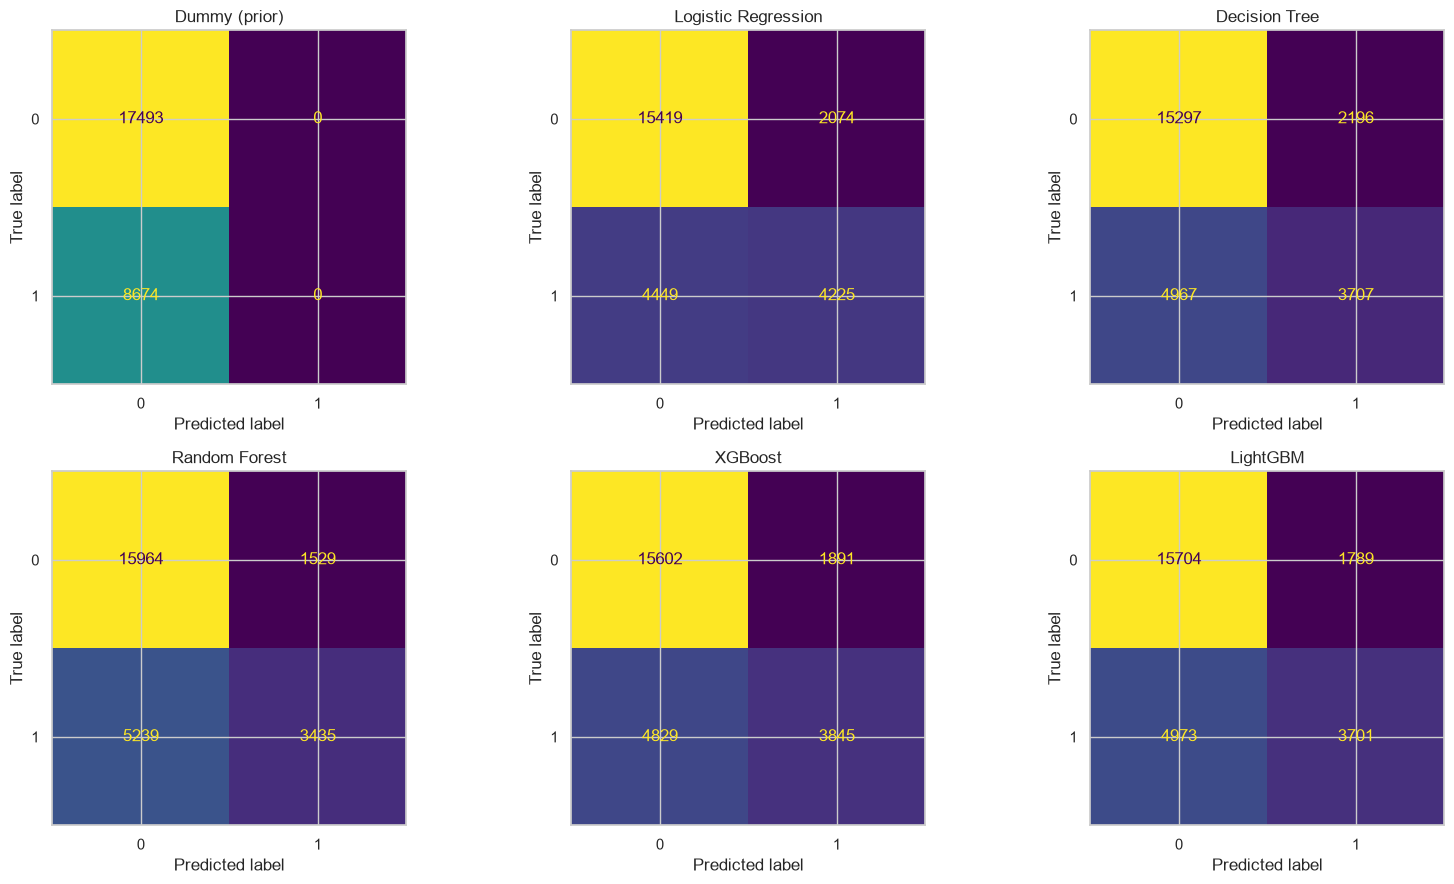

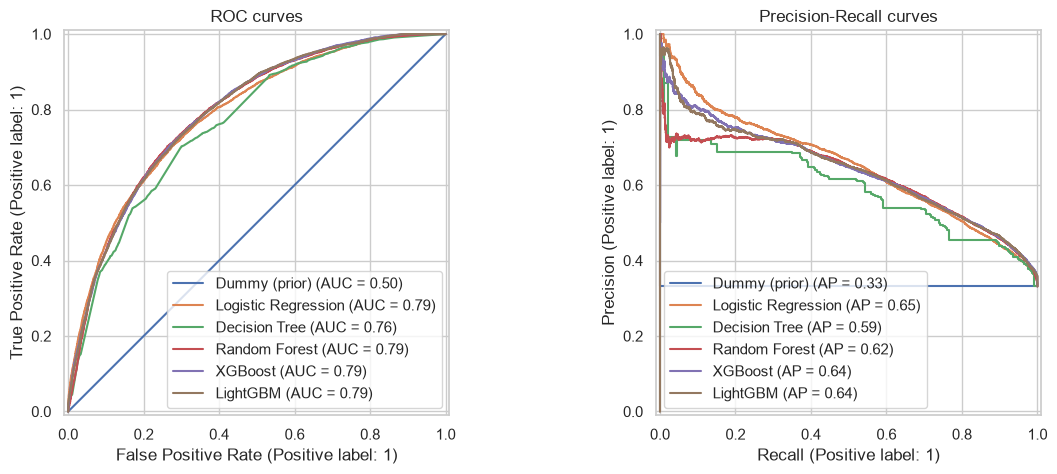

In [10]:
names = list(fitted_main.keys())
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a_, n in zip(ax.flat, names):
    pred = (fitted_main[n][1] >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test_main, pred, ax=a_, colorbar=False)
    a_.set_title(n)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for n, (_, proba) in fitted_main.items():
    RocCurveDisplay.from_predictions(y_test_main, proba, name=n, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test_main, proba, name=n, ax=ax[1])
ax[0].set_title("ROC curves"); ax[1].set_title("Precision-Recall curves")
plt.show()

## 9. Feature importance (permutation, original columns)

Best model by PR-AUC: Logistic Regression


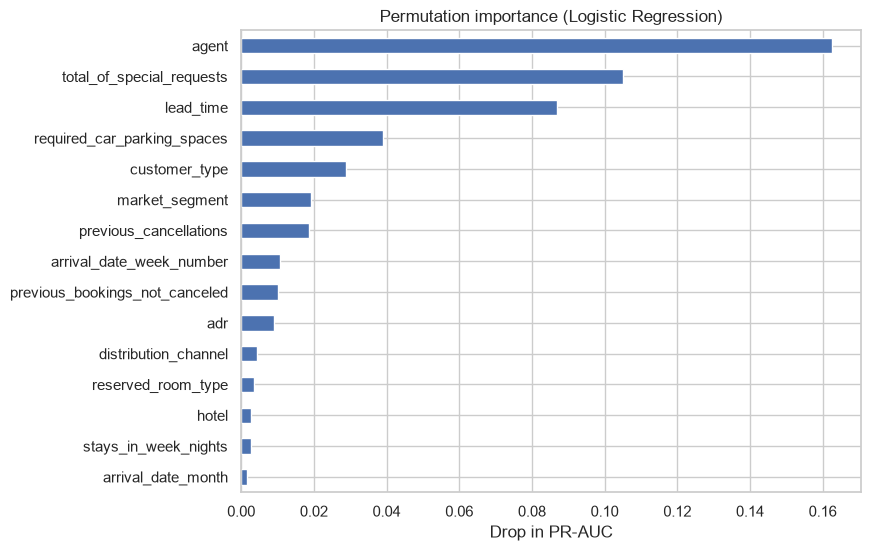

In [11]:
best_name = res_main[res_main["model"] != "Dummy (prior)"].sort_values("pr_auc", ascending=False).iloc[0]["model"]
print("Best model by PR-AUC:", best_name)
best_pipe = fitted_main[best_name][0]
samp = Xte.sample(min(5000, len(Xte)), random_state=SEED)
pi = permutation_importance(best_pipe, samp, yte.loc[samp.index], scoring="average_precision",
                            n_repeats=2 if FAST else 5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=samp.columns).sort_values(ascending=False).head(15)
imp[::-1].plot(kind="barh", figsize=(8, 6), title=f"Permutation importance ({best_name})")
plt.xlabel("Drop in PR-AUC"); plt.show()

**WRITE YOURSELF:** what do the top features mean for a hotel (lead time, special requests, market segment, and so on)?

## 10. Calibration and cost-based threshold
Cost values below are **assumptions**. Justify them or vary them in the report. The threshold is chosen on a validation slice taken
from the end of the training period, never on the test set.

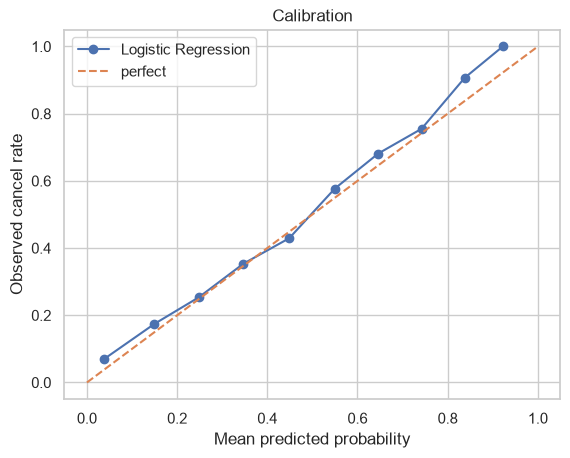

Chosen threshold: 0.53
Expected cost per booking on test, threshold 0.50: 0.3191
Expected cost per booking on test, threshold 0.53: 0.3089


,threshold 0.50,threshold 0.53
accuracy,0.7516,0.7498
precision,0.6851,0.7046
recall,0.4637,0.4224
specificity,0.8943,0.9122
f1,0.5530,0.5282
roc_auc,0.7877,0.7877
pr_auc,0.6510,0.6510
brier,0.1710,0.1710


In [12]:
COST_FN = 1.0   # missed cancellation (room left empty)
COST_FP = 2.0   # false alarm (risk of overbooking a guest who shows up)

proba_best = fitted_main[best_name][1]
frac_pos, mean_pred = calibration_curve(yte, proba_best, n_bins=10)
plt.plot(mean_pred, frac_pos, marker="o", label=best_name)
plt.plot([0, 1], [0, 1], "--", label="perfect")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed cancel rate"); plt.legend(); plt.title("Calibration"); plt.show()

tr = splits["chronological"][0]
cv_ = int(len(tr) * 0.8)
tr_a, tr_b = tr[:cv_], tr[cv_:]
pipe_v = clone(best_pipe).fit(d.loc[tr_a, cols], d.loc[tr_a, TARGET])
p_val = pipe_v.predict_proba(d.loc[tr_b, cols])[:, 1]
y_val = d.loc[tr_b, TARGET].to_numpy()


def expected_cost(y, p, t):
    pred = p >= t
    fn = ((y == 1) & ~pred).sum()
    fp = ((y == 0) & pred).sum()
    return (COST_FN * fn + COST_FP * fp) / len(y)


grid_t = np.linspace(0.05, 0.95, 91)
best_t = grid_t[int(np.argmin([expected_cost(y_val, p_val, t) for t in grid_t]))]
p_test = pipe_v.predict_proba(Xte)[:, 1]
y_te = yte.to_numpy()
print(f"Chosen threshold: {best_t:.2f}")
print(f"Expected cost per booking on test, threshold 0.50: {expected_cost(y_te, p_test, 0.5):.4f}")
print(f"Expected cost per booking on test, threshold {best_t:.2f}: {expected_cost(y_te, p_test, best_t):.4f}")
display(pd.DataFrame({"threshold 0.50": evaluate(yte, p_test, 0.5),
                      f"threshold {best_t:.2f}": evaluate(yte, p_test, best_t)}).round(4))

## 11. Answers to the project questions (WRITE YOURSELF)
1. Can booking details predict cancellation? Evidence:
2. Which model performed best, using several metrics? Evidence:
3. How much do leakage and split choice inflate results? Evidence:

## 12. Limitations and future work (WRITE YOURSELF)
Think about: single source (two Portuguese hotels, 2015 to 2017), no COVID-era data, assumed costs, seasonality gap in the split.

In [13]:
pd.concat([res_main.assign(setting="main: chronological + clean"), audit]).to_csv("all_results.csv", index=False)
print("Saved audit_results.csv and all_results.csv")

Saved audit_results.csv and all_results.csv
